In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import sys
print(sys.version)

3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]


In [3]:
%pip install -U pip setuptools wheel
%pip install -U numpy pandas scikit-learn
%pip install -U lifelines scikit-survival

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 67.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 75.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 65.6 MB/s  0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4119 sha256=2ed8fd7a752333dc8e44d7ead0fe054c2d2418c8156c10d7cea3aa0d1d38fdde
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.9.0
    Uninstalling scikit-learn-1.9.0:
      Successfully uninstalled scikit-learn-1.9.0
  Attempting uninstall: pandas
    Found existing installation: pandas 3.0.3
    Uninstalling pandas-3.0.3:
      Successfully uninstalled pandas-3.0.3
   ━━━━

In [4]:
import os
import json
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test
from lifelines.utils import concordance_index

from sksurv.util import Surv
from sksurv.metrics import integrated_brier_score, cumulative_dynamic_auc

In [5]:
PROCESSED_DATA_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/"
SELECTKBEST_OUTPUT_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Processed Data/SelectKBest/"
RESULTS_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/"
MODEL_DIR = "/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Model/SelectKBest/"

os.makedirs(SELECTKBEST_OUTPUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

TRAIN_PATH = SELECTKBEST_OUTPUT_DIR + "hcc_selectkbest_train_selected.csv"
TEST_PATH = SELECTKBEST_OUTPUT_DIR + "hcc_selectkbest_test_selected.csv"
MODEL_PATH = MODEL_DIR + "hcc_selectkbest_deepsurv_model.pth"

PREDICTION_OUTPUT_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_test_predictions.csv"
METRICS_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_metrics.csv"
KM_PLOT_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_km_risk_groups.png"
RISK_HIST_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_risk_histogram.png"
ORDERED_RISK_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_ordered_risk_scores.png"
SURVIVAL_CURVE_PLOT_PATH = RESULTS_DIR + "hcc_selectkbest_deepsurv_example_survival_curves.png"

DURATION_COL = "OS_MONTHS"
EVENT_COL = "OS_EVENT"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [6]:
train_data = pd.read_csv(TRAIN_PATH)
test_data = pd.read_csv(TEST_PATH)

print("Train data shape:", train_data.shape)
print("Test data shape:", test_data.shape)

test_data.head()

Train data shape: (1085, 52)
Test data shape: (272, 52)


,SAMPLE_COVERAGE,TUMOR_SIZE,MUT_ALB,MUT_ARID1A,MUT_ARID1B,MUT_UPF1,MUT_WHSC1,MUT_ZFHX3,CNA_CDKN2A,CNA_KMT2B,...,RESECTION_MARGIN_R0,NEOADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_,ADJUVANT_SYSTEMIC_THERAPY_No,ADJUVANT_SYSTEMIC_THERAPY_Yes,PALLIATIVE_SYSTEMIC_THERPAY_,PALLIATIVE_SYSTEMIC_THERPAY_No,PALLIATIVE_SYSTEMIC_THERPAY_Yes,OS_MONTHS,OS_EVENT
0,913.0,6.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,28.980,1
1,560.0,13.7,0.0,0.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,5.952,1
2,592.0,4.5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,9.984,0
3,642.0,6.7,0.0,0.0,0.0,0.0,0.0,0.0,-2.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,23.652,1
4,634.0,4.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,...,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,36.696,0


In [7]:
print("Train missing values:", int(train_data.isna().sum().sum()))
print("Test missing values:", int(test_data.isna().sum().sum()))

print("\nTrain OS_EVENT distribution:")
print(train_data[EVENT_COL].value_counts())

print("\nTest OS_EVENT distribution:")
print(test_data[EVENT_COL].value_counts())

Train missing values: 0
Test missing values: 0

Train OS_EVENT distribution:
OS_EVENT
1    641
0    444
Name: count, dtype: int64

Test OS_EVENT distribution:
OS_EVENT
1    161
0    111
Name: count, dtype: int64


In [8]:
for id_col in ["PATIENT_ID", "SAMPLE_ID"]:
    assert id_col not in train_data.columns, f"{id_col} found in train_data"
    assert id_col not in test_data.columns, f"{id_col} found in test_data"

print("ID leakage guard passed.")

ID leakage guard passed.


In [9]:
class DeepSurv(nn.Module):
    def __init__(self, input_dim, hidden_layers, dropout_rate, activation_name):
        super(DeepSurv, self).__init__()

        activation_map = {
            "ReLU": nn.ReLU,
            "LeakyReLU": nn.LeakyReLU,
            "ELU": nn.ELU,
            "SELU": nn.SELU
        }

        layers = []
        current_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(current_dim, hidden_dim))
            layers.append(activation_map[activation_name]())
            if dropout_rate > 0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = hidden_dim

        self.feature_extractor = nn.Sequential(*layers)
        self.output_layer = nn.Linear(current_dim, 1)

    def forward(self, x):
        x = self.feature_extractor(x)
        return self.output_layer(x)

In [10]:
checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

INPUT_DIM = checkpoint["input_dim"]
HIDDEN_LAYERS = checkpoint["hidden_layers"]
DROPOUT_RATE = checkpoint["dropout_rate"]
ACTIVATION = checkpoint["activation"]
GENES = checkpoint["feature_columns"]

print("Input dimension:", INPUT_DIM)
print("Hidden layers:", HIDDEN_LAYERS)
print("Dropout rate:", DROPOUT_RATE)
print("Activation:", ACTIVATION)
print("Feature count:", len(GENES))

Input dimension: 50
Hidden layers: [128, 64]
Dropout rate: 0.0
Activation: LeakyReLU
Feature count: 50


In [11]:
model = DeepSurv(
    input_dim=INPUT_DIM,
    hidden_layers=HIDDEN_LAYERS,
    dropout_rate=DROPOUT_RATE,
    activation_name=ACTIVATION
).to(DEVICE)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print("Model loaded successfully")

Model loaded successfully


In [12]:
X_train = train_data[GENES].copy()
y_train = train_data[[DURATION_COL, EVENT_COL]].copy()

X_test = test_data[GENES].copy()
y_test = test_data[[DURATION_COL, EVENT_COL]].copy()

print("Train feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)

Train feature shape: (1085, 50)
Test feature shape: (272, 50)


In [13]:
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32).to(DEVICE)

with torch.no_grad():
    test_preds = model(X_test_tensor).cpu().numpy().reshape(-1)

test_c_index = concordance_index(
    y_test[DURATION_COL].values,
    -test_preds,
    y_test[EVENT_COL].values
)

print(f"Test Concordance Index: {test_c_index:.4f}")

Test Concordance Index: 0.7293


In [14]:
evaluation_df = test_data[[DURATION_COL, EVENT_COL]].copy()
evaluation_df["risk_score"] = test_preds

print("Evaluation dataframe shape:", evaluation_df.shape)
evaluation_df.head()

Evaluation dataframe shape: (272, 3)


,OS_MONTHS,OS_EVENT,risk_score
0,28.980,1,2.467288
1,5.952,1,3.344712
2,9.984,0,1.676703
3,23.652,1,3.454284
4,36.696,0,-0.190578


In [15]:
y_train_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, train_data)
y_test_sksurv = Surv.from_dataframe(EVENT_COL, DURATION_COL, test_data)

In [16]:
def compute_baseline_survival(model, X_train, durations_train, events_train):
    X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        train_risk_scores = model(X_train_tensor).cpu().numpy().reshape(-1)

    unique_event_times = np.sort(np.unique(durations_train[events_train == 1]))
    cumulative_hazard = []
    running_hazard = 0.0

    for time_point in unique_event_times:
        events_at_time = np.sum((durations_train == time_point) & (events_train == 1))
        at_risk_mask = durations_train >= time_point
        risk_sum = np.sum(np.exp(train_risk_scores[at_risk_mask]))

        running_hazard += events_at_time / risk_sum
        cumulative_hazard.append(running_hazard)

    baseline_survival = np.exp(-np.array(cumulative_hazard))
    return unique_event_times, baseline_survival

In [17]:
def predict_survival_curves(model, X_input, event_times, baseline_survival):
    X_input_tensor = torch.tensor(X_input.values, dtype=torch.float32).to(DEVICE)

    with torch.no_grad():
        risk_scores = model(X_input_tensor).cpu().numpy().reshape(-1)

    survival_curves = []

    for risk_score in risk_scores:
        hazard_ratio = np.exp(risk_score)
        patient_survival = baseline_survival ** hazard_ratio
        survival_curves.append(patient_survival)

    return np.array(survival_curves)

In [18]:
event_times, baseline_survival = compute_baseline_survival(
    model,
    X_train,
    y_train[DURATION_COL].values,
    y_train[EVENT_COL].values
)

survival_curves = predict_survival_curves(
    model,
    X_test,
    event_times,
    baseline_survival
)

print("Number of baseline event times:", len(event_times))
print("Survival curve matrix shape:", survival_curves.shape)

Number of baseline event times: 519
Survival curve matrix shape: (272, 519)


In [19]:
requested_time_points = np.array([1, 3, 5]) * 12
max_eval_time = min(train_data[DURATION_COL].max(), test_data[DURATION_COL].max())

time_points = requested_time_points[requested_time_points < max_eval_time]

if len(time_points) == 0:
    raise ValueError("No valid AUC time points are within observed follow-up range.")

print("AUC time points used (months):", time_points)

AUC time points used (months): [12 36 60]


In [20]:
valid_time_mask = (event_times >= 1) & (event_times < max_eval_time)
time_grid = event_times[valid_time_mask]
surv_probs = survival_curves[:, valid_time_mask]

if len(time_grid) == 0:
    raise ValueError("Time grid for IBS is empty. Check survival follow-up range.")

print("IBS time grid length:", len(time_grid))
print("Survival probability matrix shape:", surv_probs.shape)

IBS time grid length: 516
Survival probability matrix shape: (272, 516)


In [21]:
ibs = integrated_brier_score(y_train_sksurv, y_test_sksurv, surv_probs, time_grid)
print(f"Integrated Brier Score: {ibs:.4f}")

Integrated Brier Score: 0.1288


In [22]:
auc_scores, mean_auc = cumulative_dynamic_auc(
    y_train_sksurv,
    y_test_sksurv,
    test_preds,
    time_points
)

for t, auc in zip(time_points, auc_scores):
    print(f"AUC at {int(t/12)} years: {auc:.4f}")

print(f"Mean time-dependent AUC: {mean_auc:.4f}")

AUC at 1 years: 0.7886
AUC at 3 years: 0.8381
AUC at 5 years: 0.8290
Mean time-dependent AUC: 0.8236


In [23]:
median_risk = evaluation_df["risk_score"].median()

evaluation_df["risk_group"] = evaluation_df["risk_score"].apply(
    lambda x: "High risk" if x >= median_risk else "Low risk"
)

evaluation_df["risk_group"].value_counts()

,count
risk_group,
High risk,136
Low risk,136


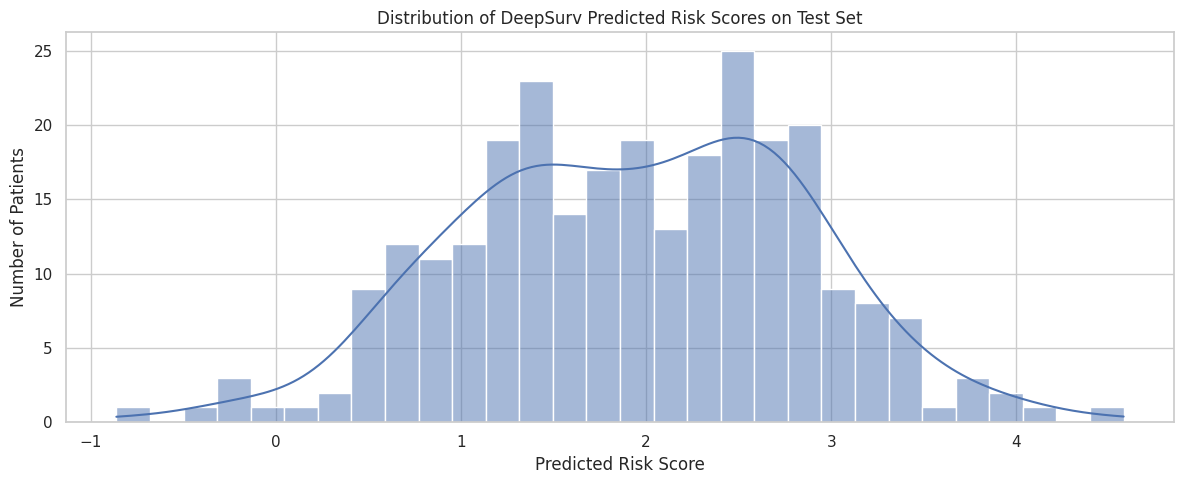

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_risk_histogram.png'

In [24]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 5))
sns.histplot(evaluation_df["risk_score"], bins=30, kde=True)
plt.title("Distribution of DeepSurv Predicted Risk Scores on Test Set")
plt.xlabel("Predicted Risk Score")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.savefig(RISK_HIST_PATH, dpi=300, bbox_inches="tight")
plt.show()

RISK_HIST_PATH

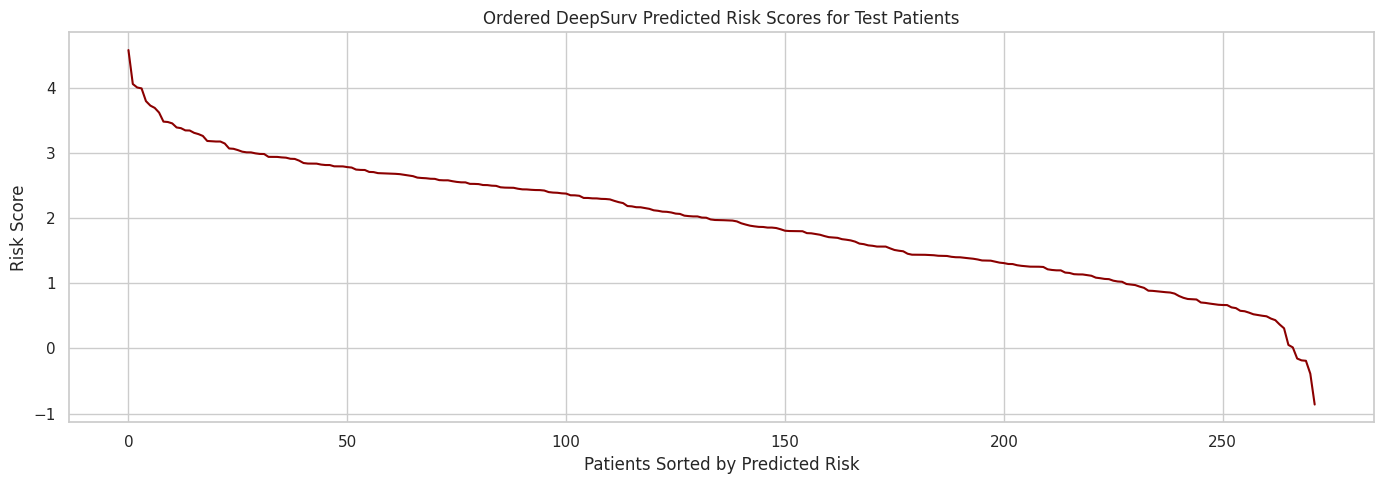

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_ordered_risk_scores.png'

In [25]:
evaluation_df_sorted = evaluation_df.sort_values("risk_score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(evaluation_df_sorted["risk_score"].values, color="darkred")
plt.title("Ordered DeepSurv Predicted Risk Scores for Test Patients")
plt.xlabel("Patients Sorted by Predicted Risk")
plt.ylabel("Risk Score")
plt.tight_layout()
plt.savefig(ORDERED_RISK_PATH, dpi=300, bbox_inches="tight")
plt.show()

ORDERED_RISK_PATH

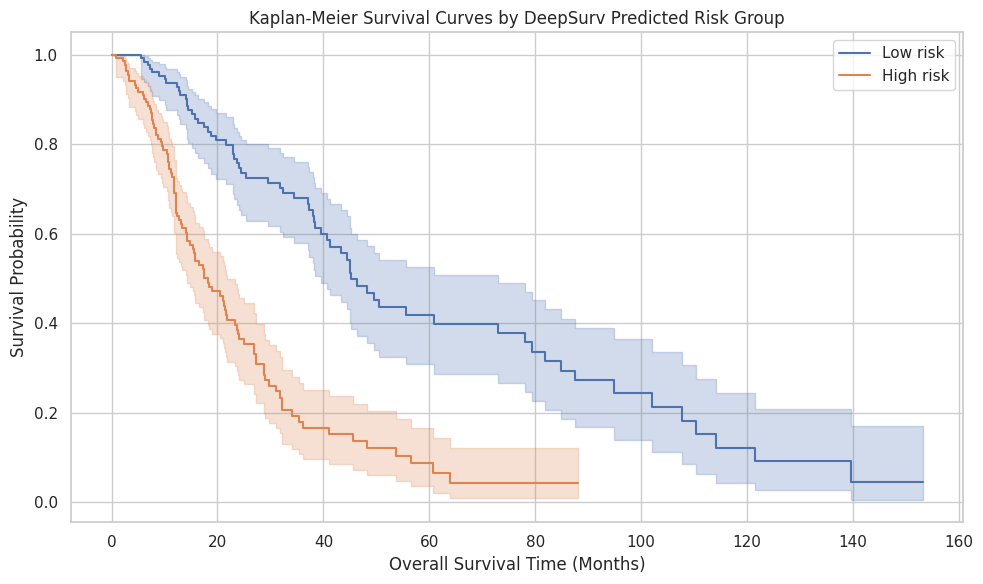

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_km_risk_groups.png'

In [26]:
kmf = KaplanMeierFitter()

plt.figure(figsize=(10, 6))

for group_name in ["Low risk", "High risk"]:
    group_df = evaluation_df[evaluation_df["risk_group"] == group_name]

    kmf.fit(
        durations=group_df[DURATION_COL],
        event_observed=group_df[EVENT_COL],
        label=group_name
    )
    kmf.plot_survival_function(ci_show=True)

plt.title("Kaplan-Meier Survival Curves by DeepSurv Predicted Risk Group")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.grid(True)
plt.tight_layout()
plt.savefig(KM_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

KM_PLOT_PATH

In [27]:
low_risk_df = evaluation_df[evaluation_df["risk_group"] == "Low risk"]
high_risk_df = evaluation_df[evaluation_df["risk_group"] == "High risk"]

logrank_result = logrank_test(
    low_risk_df[DURATION_COL],
    high_risk_df[DURATION_COL],
    event_observed_A=low_risk_df[EVENT_COL],
    event_observed_B=high_risk_df[EVENT_COL]
)

print("Log-rank test p-value:", logrank_result.p_value)

Log-rank test p-value: 1.8112672647920723e-13


In [28]:
selected_times = [12, 24, 36, 60]

for month in selected_times:
    closest_index = np.argmin(np.abs(event_times - month))
    evaluation_df[f"survival_prob_{month}m"] = survival_curves[:, closest_index]

evaluation_df.head()

,OS_MONTHS,OS_EVENT,risk_score,risk_group,survival_prob_12m,survival_prob_24m,survival_prob_36m,survival_prob_60m
0,28.980,1,2.467288,High risk,0.742217,0.451129,0.253065,0.074567
1,5.952,1,3.344712,High risk,0.488277,0.147468,0.036724,0.001945
2,9.984,0,1.676703,Low risk,0.873525,0.696944,0.536190,0.308042
3,23.652,1,3.454284,High risk,0.449380,0.118150,0.025048,0.000944
4,36.696,0,-0.190578,Low risk,0.979320,0.945730,0.908172,0.833620


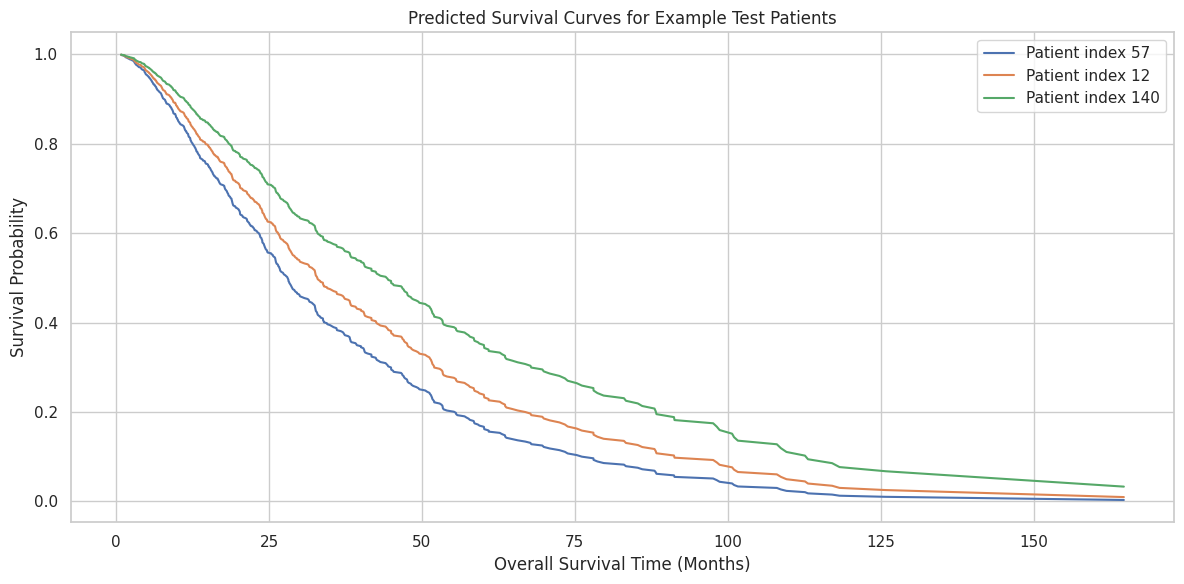

'/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_example_survival_curves.png'

In [29]:
import random

random.seed(42)
example_patients = random.sample(range(len(test_data)), 3)

plt.figure(figsize=(12, 6))

for patient_index in example_patients:
    plt.plot(
        event_times,
        survival_curves[patient_index],
        label=f"Patient index {patient_index}"
    )

plt.title("Predicted Survival Curves for Example Test Patients")
plt.xlabel("Overall Survival Time (Months)")
plt.ylabel("Survival Probability")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(SURVIVAL_CURVE_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

SURVIVAL_CURVE_PLOT_PATH

In [30]:
evaluation_df.to_csv(PREDICTION_OUTPUT_PATH, index=False)

print("Saved predictions to:", PREDICTION_OUTPUT_PATH)

Saved predictions to: /content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_test_predictions.csv


In [31]:
metrics_rows = [
    {"metric": "C-index", "value": test_c_index},
    {"metric": "IBS", "value": ibs}
]

for t, auc in zip(time_points, auc_scores):
    metrics_rows.append({
        "metric": f"AUC_{int(t/12)}_year",
        "value": auc
    })

metrics_rows.append({"metric": "Mean_time_dependent_AUC", "value": mean_auc})
metrics_rows.append({"metric": "Log-rank_p_value", "value": logrank_result.p_value})

metrics_df = pd.DataFrame(metrics_rows)
metrics_df.to_csv(METRICS_PATH, index=False)

metrics_df

,metric,value
0,C-index,7.292954e-01
1,IBS,1.288272e-01
2,AUC_1_year,7.886231e-01
3,AUC_3_year,8.380889e-01
4,AUC_5_year,8.290197e-01
5,Mean_time_dependent_AUC,8.236367e-01
6,Log-rank_p_value,1.811267e-13


In [32]:
PREDICTION_OUTPUT_PATH, METRICS_PATH

('/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_test_predictions.csv',
 '/content/drive/MyDrive/IEEE Project/Hepatocellular Carcinoma/Results/SelectKBest/hcc_selectkbest_deepsurv_metrics.csv')

The `SelectKBest` DeepSurv evaluation notebook tested the final saved neural survival model on the untouched held-out test set and completed the full survival evaluation workflow. This notebook used the trained DeepSurv model to generate patient-level risk scores and survival curves, then assessed performance using discrimination metrics, survival-probability error, and Kaplan-Meier risk stratification.

A few structural outputs confirm the evaluation was performed correctly. The model reconstructed survival over `519` baseline event times, producing a survival-curve matrix of shape `(272, 519)`, which matches the `272` test patients. For IBS, the notebook used a time grid of length `516`, giving a survival-probability matrix of shape `(272, 516)`. This shows the model was not evaluated only as a ranker, but also as a full time-to-event predictor across the follow-up window.

The final test results were:
- C-index: `0.7293`
- IBS: `0.1288`
- AUC at 1 year: `0.7886`
- AUC at 3 years: `0.8381`
- AUC at 5 years: `0.8290`
- Mean time-dependent AUC: `0.8236`
- Log-rank p-value: `1.8113e-13`

These results indicate that the `SelectKBest` DeepSurv model generalized well to unseen patients. The test C-index of `0.7293` shows good overall risk-ranking ability. It is slightly lower than the corresponding `SelectKBest` CoxPH C-index, but still firmly in a strong range for survival discrimination. The IBS of `0.1288` is also good, indicating reasonable overall survival-probability prediction quality across time.

The time-dependent AUC profile is one of the stronger parts of the result. The model achieved:
- `0.7886` at 1 year
- `0.8381` at 3 years
- `0.8290` at 5 years

This suggests that the model is especially strong at medium- and longer-term discrimination, with 3-year and 5-year performance both above `0.82`. The 1-year AUC is a bit lower than those later horizons, which is an interesting pattern and somewhat different from the `Exp_1` behavior. In this `SelectKBest` branch, the neural model seems to separate later survival outcomes especially well.

The mean time-dependent AUC of `0.8236` supports that conclusion and shows that overall discrimination across the major clinical time points is strong. The log-rank p-value of `1.81e-13` is extremely small, confirming that the predicted high-risk and low-risk groups have clearly separated Kaplan-Meier survival curves. So the model’s risk scores are not just statistically adequate, but clinically meaningful for stratifying patients into distinct survival groups.

Overall, this notebook shows that the `SelectKBest` DeepSurv pipeline was successful end to end. The tuned architecture generalized well, produced strong discrimination across 1-, 3-, and 5-year horizons, and yielded highly significant survival separation between predicted risk groups. The key conclusion is that `SelectKBest` supports a robust DeepSurv model, with particularly strong intermediate- and long-term prognostic discrimination on the held-out test set.